# Combining infrequent categories

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    TargetEncoder
)
from sklearn.feature_extraction import FeatureHasher

from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.compose import make_column_transformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, cross_val_score


In [2]:
# Revisit the OKCupid data
df = pd.read_csv("../04_categorical/profiles_revised.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 59946 entries, 0 to 59945
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          59946 non-null  int64  
 1   body_type    54650 non-null  str    
 2   diet         35551 non-null  str    
 3   drinks       56961 non-null  str    
 4   drugs        45866 non-null  str    
 5   education    53318 non-null  str    
 6   ethnicity    54266 non-null  str    
 7   height       59943 non-null  float64
 8   income       59946 non-null  int64  
 9   job          51748 non-null  str    
 10  offspring    24385 non-null  str    
 11  orientation  59946 non-null  str    
 12  pets         40025 non-null  str    
 13  religion     39720 non-null  str    
 14  sex          59946 non-null  str    
 15  sign         48890 non-null  str    
 16  smokes       54434 non-null  str    
 17  speaks       59896 non-null  str    
 18  status       59946 non-null  str    
dtypes: float64(1), 

In [3]:
# Stratify on the drinks category because that's what we did in lecture 4
df["drinks"] = df["drinks"].replace(np.nan, "Unknown")
train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["drinks"])

In [4]:
# revisit cardinality
print("Feature     Count")
# Assuming that str is categorical, could be bad assumption
for feat in train.select_dtypes(include="str").columns:
    print(f"{feat:12}{train[feat].nunique()}")

Feature     Count
body_type   12
diet        18
drinks      7
drugs       3
education   32
ethnicity   208
job         21
offspring   15
orientation 3
pets        15
religion    45
sex         2
sign        48
smokes      5
speaks      6440
status      5

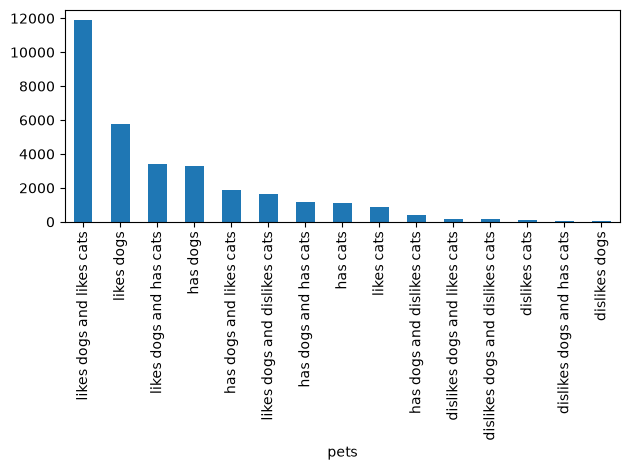

In [5]:
# let's check the "pets" category
ax = train["pets"].value_counts().plot.bar()
plt.tight_layout()
plt.savefig("../../img/08-pets-dist.png")

In [6]:
# TODO: see how it changes with max_categories
pet_enc = OneHotEncoder(sparse_output=False, max_categories=12).set_output(transform="pandas")
one_hot_pets = pet_enc.fit_transform(train[["pets"]])
one_hot_pets

47956 rows × 12 columns

In [7]:
one_hot_pets.sum(axis=0)

pets_has cats                         1118.0
pets_has dogs                         3311.0
pets_has dogs and dislikes cats        424.0
pets_has dogs and has cats            1192.0
pets_has dogs and likes cats          1899.0
pets_likes cats                        850.0
pets_likes dogs                       5780.0
pets_likes dogs and dislikes cats     1637.0
pets_likes dogs and has cats          3439.0
pets_likes dogs and likes cats       11894.0
pets_nan                             15873.0
pets_infrequent_sklearn                539.0
dtype: float64

## Feature Hashing

For very high cardinality strings (or other iterables)

In [8]:
train["speaks"].value_counts().head(50)

speaks
english                                                    17487
english (fluently)                                          5355
english (fluently), spanish (poorly)                        1644
english (fluently), spanish (okay)                          1532
english (fluently), spanish (fluently)                      1031
english, spanish                                             695
english (fluently), french (poorly)                          593
english, spanish (okay)                                      530
english, spanish (poorly)                                    488
english (fluently), chinese (fluently)                       433
english (fluently), french (okay)                            431
english (fluently), chinese (okay)                           341
english (poorly)                                             246
english (okay)                                               241
english, chinese                                             237
english (fluently)

In [9]:
# feature hasher needs lists of strings, and can't handle nans
train.fillna({"speaks": ""}, inplace=True)
language_enc = FeatureHasher(n_features=18, input_type="string")
lang_hash = language_enc.fit_transform(train["speaks"].str.split(",")).todense()

In [10]:
test = [
    # ["french (okay)"], 
    ["french (okay)", "english"], 
    # ["english (fluently)", "spanish (poorly)"],
    ["english", "python (okay)", "japanese", "c++"], 
    # ["a", "b", "c", "d", "1234"],
    ["english", "french"]
]
language_enc.transform(test).todense()

matrix([[ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,
          0.,  0., -1.,  0.,  0.],
        [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,  1.,
          0., -1.,  0.,  0., -1.],
        [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,
         -1.,  0.,  0.,  0.,  0.]])

## Target encoding

For high cardinal features with a relationship to the target

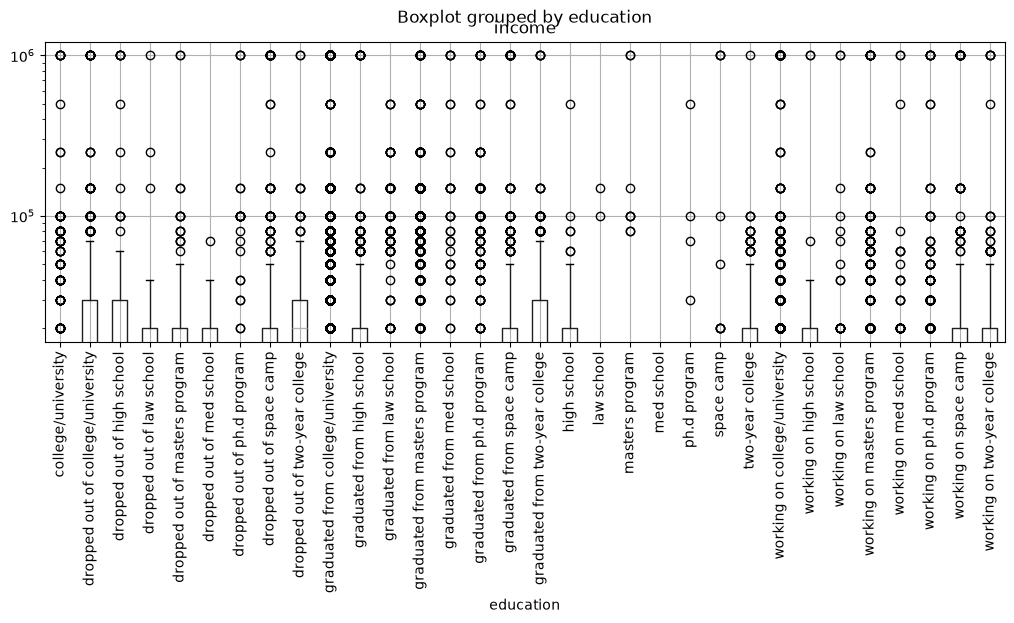

In [11]:
# income vs education
ax = train.boxplot(column="income", by="education", rot=90, figsize=(12, 4))
ax.set_yscale("log")
# hmmm... not sure if this is at all useful

In [12]:
edu_encoder = TargetEncoder(target_type="continuous")

# note: this should replace -1 with nan, but it's not behaving
train["education"] = train["education"].replace(-1, np.nan)
# important! Use fit_transform with this type of encoder
edu_feat = edu_encoder.fit_transform(train[["education"]],train["income"])
order = edu_encoder.encodings_[0].argsort()

for o in order:
    print(f"{edu_encoder.categories_[0][o]:35} ${edu_encoder.encodings_[0][o]:,.2f}")

med school                          $-1.00
                                nan $11,432.16
working on law school               $13,000.29
dropped out of med school           $13,669.76
working on ph.d program             $15,186.34
working on two-year college         $15,198.78
graduated from law school           $15,288.82
working on masters program          $16,068.26
law school                          $16,712.13
high school                         $17,958.64
graduated from masters program      $18,420.80
working on med school               $18,879.45
graduated from college/university   $19,039.02
graduated from two-year college     $19,066.97
two-year college                    $19,109.49
working on college/university       $19,977.21
college/university                  $20,295.56
graduated from med school           $21,693.70
graduated from high school          $22,640.39
masters program                     $24,772.04
graduated from ph.d program         $26,225.31
dropped out of ma

# Principal Component Analysis (PCA) on Iris Dataset

This example shows a well known decomposition technique known as
Principal Component Analysis (PCA) on the [Iris
dataset](https://en.wikipedia.org/wiki/Iris_flower_data_set).

This dataset is made of 4 features: sepal length, sepal width, petal
length, petal width. We use PCA to project this 4 feature space into a
3-dimensional space.

    # Authors: The scikit-learn developers
    # SPDX-License-Identifier: BSD-3-Clause

## Loading the Iris dataset

The Iris dataset is directly available as part of scikit-learn. It can
be loaded using the :func:`~sklearn.datasets.load_iris` function. With
the default parameters, a :class:`~sklearn.utils.Bunch` object is
returned, containing the data, the target values, the feature names, and
the target names.

## Plot of pairs of features of the Iris dataset

Let’s first plot the pairs of features of the Iris dataset.

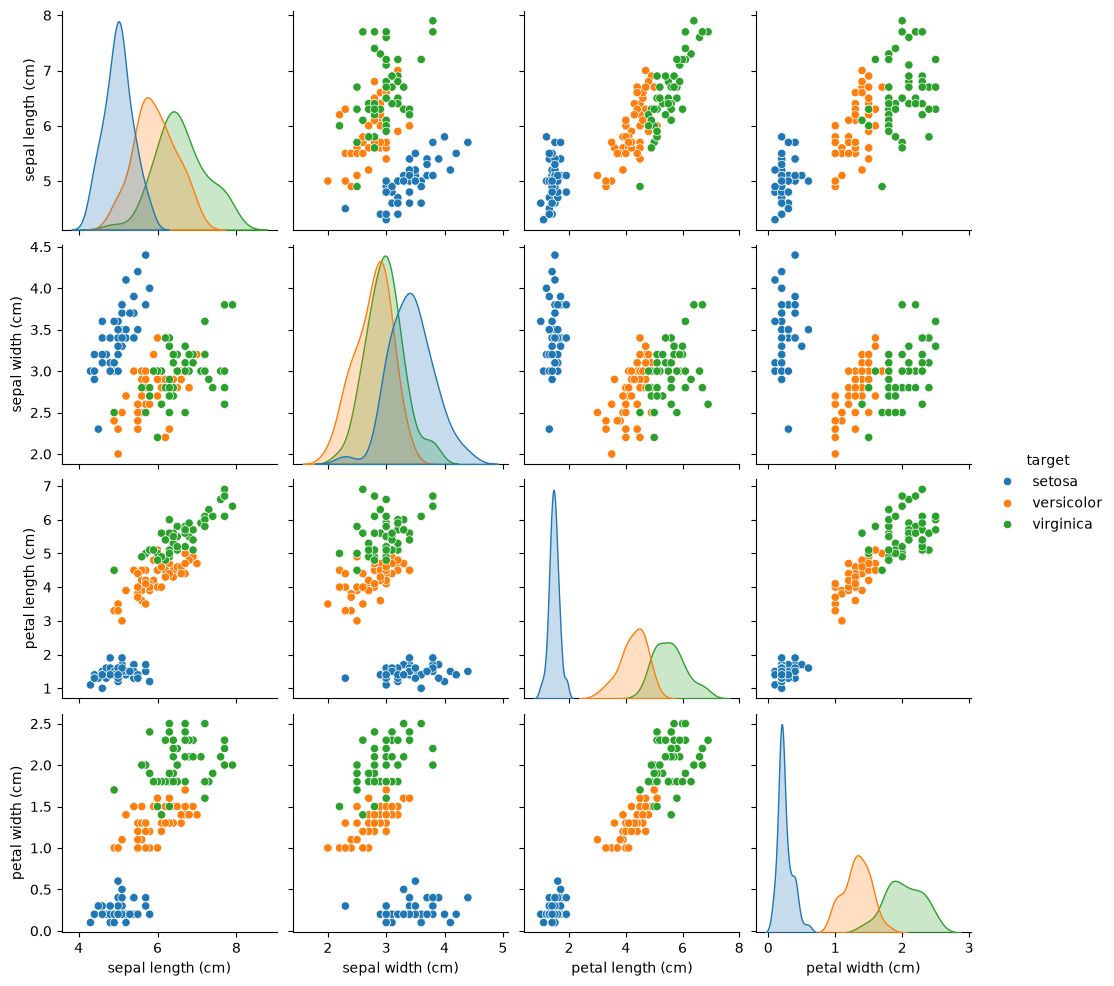

In [13]:
import seaborn as sns
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)

# Rename classes using the iris target names
iris.frame["target"] = iris.target_names[iris.target]
_ = sns.pairplot(iris.frame, hue="target")

Each data point on each scatter plot refers to one of the 150 iris
flowers in the dataset, with the color indicating their respective
type(Setosa, Versicolor, and Virginica).

You can already see a pattern regarding the Setosa type, which is easily
identifiable based on its short and wide sepal. Only considering these
two dimensions, sepal width and length, there’s still overlap between
the Versicolor and Virginica types.

The diagonal of the plot shows the distribution of each feature. We
observe that the petal width and the petal length are the most
discriminant features for the three types.

## Plot a PCA representation

Let’s apply a Principal Component Analysis (PCA) to the iris dataset and
then plot the irises across the first three principal components. This
will allow us to better differentiate among the three types!

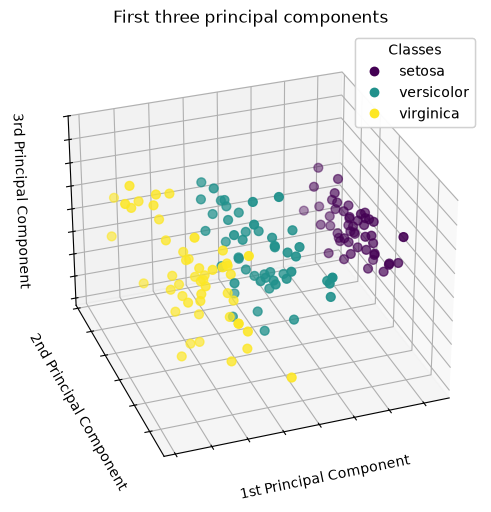

In [14]:
import matplotlib.pyplot as plt

# unused but required import for doing 3d projections with matplotlib < 3.2
import mpl_toolkits.mplot3d  # noqa: F401

from sklearn.decomposition import PCA

fig = plt.figure(1, figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d", elev=-150, azim=110)

pca = PCA()
X_reduced = pca.fit_transform(iris.data)
scatter = ax.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    X_reduced[:, 2],
    c=iris.target,
    s=40,
)

ax.set(
    title="First three principal components",
    xlabel="1st Principal Component",
    ylabel="2nd Principal Component",
    zlabel="3rd Principal Component",
)
ax.xaxis.set_ticklabels([])
ax.yaxis.set_ticklabels([])
ax.zaxis.set_ticklabels([])

# Add a legend
legend1 = ax.legend(
    scatter.legend_elements()[0],
    iris.target_names.tolist(),
    loc="upper right",
    title="Classes",
)
ax.add_artist(legend1)

plt.show()

PCA will create 3 new features that are a linear combination of the 4
original features. In addition, this transformation maximizes the
variance. With this transformation, we can identify each species using
only the first principal component.

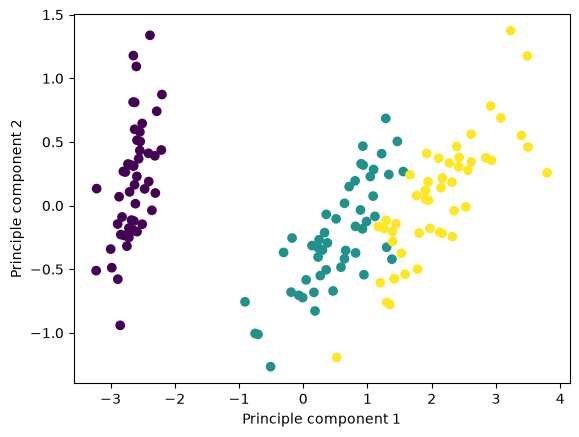

In [15]:
plt.scatter(X_reduced[:,0], X_reduced[:,1],c=iris.target)
plt.xlabel("Principle component 1")
plt.ylabel("Principle component 2")

## Charlotte’s Extras

The iris demo is great, but I had a few more things to show off.

In [16]:
import numpy as np

# PCA is eigendecomposition!
X_centred = iris.data - iris.data.mean(axis = 0)
C =  np.cov(X_centred, rowvar=False)
Lambda, Q = np.linalg.eig(C)
print(Lambda)
print(pca.explained_variance_)

# eigenvalues are columns, pca components are rows for some reason
print(Q)
print(pca.components_.T)


[4.22824171+0.j 0.24267075+0.j 0.0782095 +0.j 0.02383509+0.j]
[4.22824171 0.24267075 0.0782095  0.02383509]
[[ 0.36138659+0.j -0.65658877+0.j -0.58202985+0.j  0.31548719+0.j]
 [-0.08452251+0.j -0.73016143+0.j  0.59791083+0.j -0.3197231 +0.j]
 [ 0.85667061+0.j  0.17337266+0.j  0.07623608+0.j -0.47983899+0.j]
 [ 0.3582892 +0.j  0.07548102+0.j  0.54583143+0.j  0.75365743+0.j]]
[[ 0.36138659  0.65658877 -0.58202985  0.31548719]
 [-0.08452251  0.73016143  0.59791083 -0.3197231 ]
 [ 0.85667061 -0.17337266  0.07623608 -0.47983899]
 [ 0.3582892  -0.07548102  0.54583143  0.75365743]]

c:\Users\ccurtis\Documents\f26\venv\Lib\site-packages\matplotlib\cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\ccurtis\Documents\f26\venv\Lib\site-packages\matplotlib\collections.py:205: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)

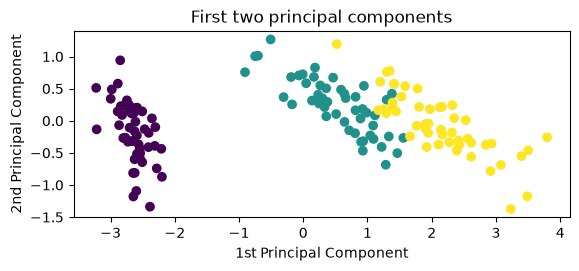

In [17]:
# eigenvalue version - same, just flipped
X_eig = (X_centred @ Q).values
fig, ax = plt.subplots()
ax.scatter(
    X_eig[:, 0],
    X_eig[:, 1],
    c=iris.target
)
ax.set_aspect("equal")
plt.title("First two principal components")
plt.xlabel("1st Principal Component")
plt.ylabel("2nd Principal Component") 

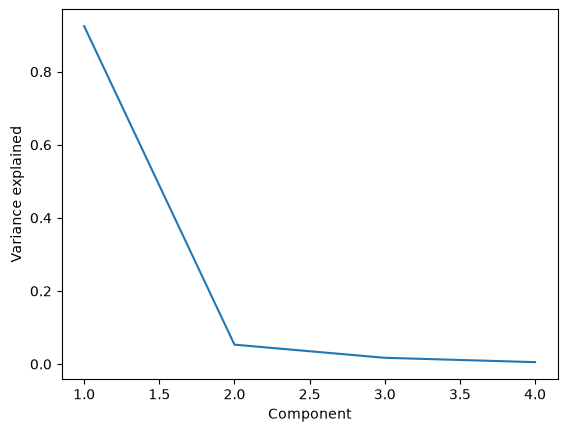

In [18]:
# Plot the explained variance ratio
plt.figure()
plt.plot(range(1, 5), pca.explained_variance_ratio_)
plt.ylabel("Variance explained")
plt.xlabel("Component")

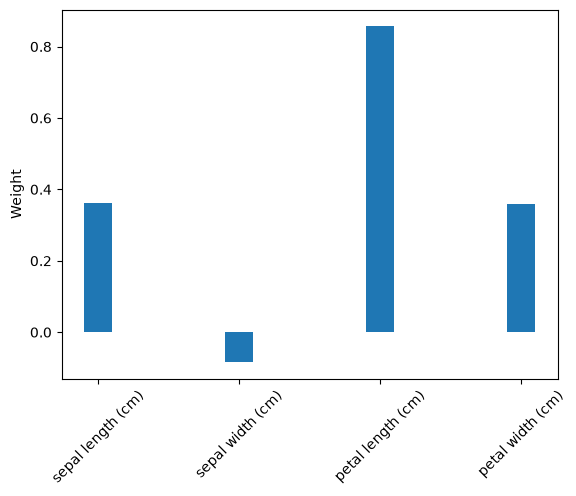

In [19]:
# What is that first one?
plt.bar(range(4), pca.components_[0], width=0.2)
plt.xticks(range(4), iris.feature_names, rotation=45)
plt.ylabel("Weight")

## LDA

Linear Discriminant Analysis (LDA) is similar, but maximizes
between-class variance instead of overall variance.

This means it relies on knowing the class labels, so it is a supervised
learning technique as well as dimensional reduction.

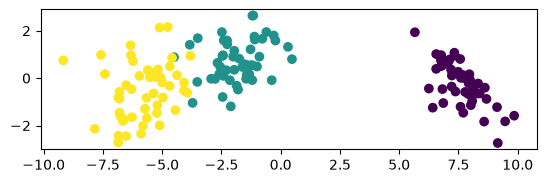

In [20]:
# What about LDA instead?
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
lda = LinearDiscriminantAnalysis()
X_lda = lda.fit_transform(iris.data, iris.target)
fig, ax = plt.subplots()
ax.scatter(
    X_lda[:, 0],
    X_lda[:, 1],
    c=iris.target
)
ax.set_aspect("equal")

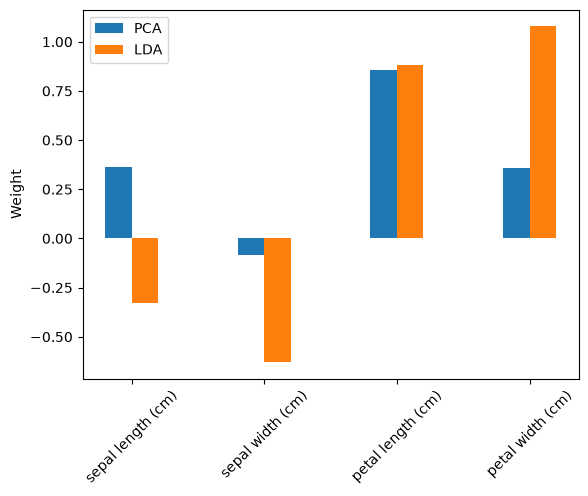

In [21]:
# Compare PCA and LDA weights
plt.bar(np.arange(4)-0.1, pca.components_[0], width=0.2, label="PCA")
plt.bar(np.arange(4)+0.1, lda.coef_[0] / lda.coef_[0].sum(), width=0.2, label="LDA")
plt.xticks(range(4), iris.feature_names, rotation=45)
plt.ylabel("Weight")
plt.legend()

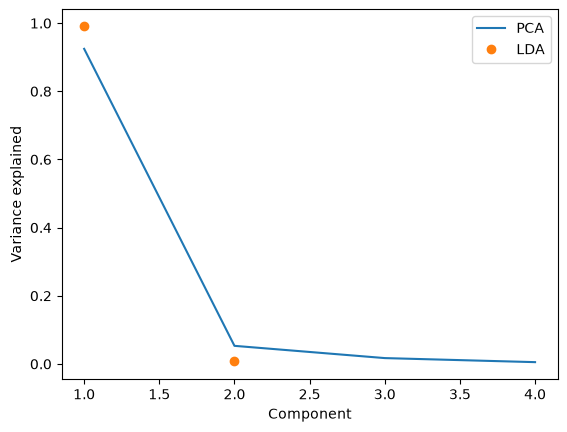

In [22]:
# Plot the explained variance ratio
plt.figure()
plt.plot(range(1, 5), pca.explained_variance_ratio_, label="PCA")
plt.plot(range(1, 3), lda.explained_variance_ratio_, "o", label="LDA")
plt.ylabel("Variance explained")
plt.xlabel("Component")
plt.legend()